In [1]:
from sklearn.preprocessing import LabelEncoder

def fillna(df):
    df["Age"] = df["Age"].fillna(df["Age"].mean())
    df["Cabin"] = df["Cabin"].fillna("N")
    df["Embarked"] = df["Embarked"].fillna(df["Embarked"].mode()[0])
    return df

def drop_features(df):
    df.drop(["PassengerId", "Name", "Ticket"], axis=1, inplace=True)
    return df

def format_features(df):
    df["Cabin"] = df["Cabin"].str[0]
    features = ["Cabin", "Sex", "Embarked"]
    for feature in features:
        encoder = LabelEncoder()
        df[feature] = encoder.fit_transform(df[feature])
    return df

def transform_features(df):
    df = fillna(df)
    df = drop_features(df)
    df = format_features(df)
    return df

In [2]:
import pandas as pd

from sklearn.model_selection import train_test_split


df = pd.read_csv("./train.csv")
y_df = df["Survived"]
X_df = df.drop("Survived",axis =1)
X_df = transform_features(X_df)

X_train,X_test,y_train, y_test = train_test_split( X_df,y_df,test_size = 0.2 ,  random_state=42)

In [3]:
import numpy as np
from sklearn.linear_model import LogisticRegression

lr_slf = LogisticRegression(solver = "liblinear")

lr_slf.fit(X_train,y_train)

pred = lr_slf.predict(X_test)

In [ ]:
from sklearn.metrics import accuracy_score,precision_score,recall_score
from sklearn.metrics import confusion_matrix

confusion = confusion_matrix(y_test, pred) # 예측
accuracy = accuracy_score(y_test,pred) # 예측 정확도
precision = precision_score(y_test, pred) # 예측 정확도 퍼센트
recall = recall_score(y_test,pred) # 실제 생존 비율 <--? 


print(confusion,accuracy,precision,recall)



[[89 16]
 [22 52]] 0.7877094972067039 0.7647058823529411 0.7027027027027027


In [5]:
pred_proba = lr_slf.predict_proba(X_test)

print("pred_proba() 결과 shape : ", pred_proba.shape)
print("pred_proba array 앞 3개의 샘플", pred_proba[:3])
pred_proba_result = np.concatenate([pred_proba, pred.reshape(-1,1)],axis =1)

print("두개의 클래스 중에서 더 큰 확률을 클래스의 값으로 예측",pred_proba_result[:3])

pred_proba() 결과 shape :  (179, 2)
pred_proba array 앞 3개의 샘플 [[0.88465353 0.11534647]
 [0.79433559 0.20566441]
 [0.85248383 0.14751617]]
두개의 클래스 중에서 더 큰 확률을 클래스의 값으로 예측 [[0.88465353 0.11534647 0.        ]
 [0.79433559 0.20566441 0.        ]
 [0.85248383 0.14751617 0.        ]]


In [6]:
from sklearn.preprocessing import Binarizer

X =[ [1,-1,2],
    [2,0,0,],
    [0,1.1,1.2]]

binarizer = Binarizer(threshold= 1.1)
print(binarizer.fit_transform(X))

[[0. 0. 1.]
 [1. 0. 0.]
 [0. 0. 1.]]


In [7]:
custom_threshold = 0.6

pred_proba_1 = pred_proba[:, 1].reshape(-1,1)
binarizer = Binarizer(threshold= custom_threshold).fit(pred_proba_1)

custom_pred = binarizer.transform(pred_proba_1)


confusion = confusion_matrix(y_test, custom_pred) # 예측
accuracy = accuracy_score(y_test,custom_pred) # 예측 정확도
precision = precision_score(y_test, custom_pred) # 예측 정확도 퍼센트
recall = recall_score(y_test,custom_pred) # 실제 생존 비율


print(confusion,accuracy,precision,recall)


[[94 11]
 [23 51]] 0.8100558659217877 0.8225806451612904 0.6891891891891891


In [8]:
from sklearn.metrics import precision_recall_curve as sklearn_precision_recall_curve
import numpy as np

pred_proba_class1 = lr_slf.predict_proba(X_test)[:, 1]
precisions, recalls, thresholds = sklearn_precision_recall_curve(
    y_test, pred_proba_class1
)

print("임계값 배열의 모양:", thresholds.shape)
print("정밀도 배열의 모양:", precisions.shape)
print("재현율 배열의 모양:", recalls.shape)
print("first 5 thresholds:", thresholds[:5])
print("first 5 precisions:", precisions[:5])
print("first 5 recalls:", recalls[:5])

thr_index = np.arange(0, len(thresholds), 15)
print("샘플 인덱스:", thr_index)
print("샘플 임계값:", np.round(thresholds[thr_index], 2))
print("샘플 임계값별 정밀도:",
      np.round(precisions[thr_index], 3))
print("샘플 임계값별 재현율:",
      np.round(recalls[thr_index], 3))


임계값 배열의 모양: (168,)
정밀도 배열의 모양: (169,)
재현율 배열의 모양: (169,)
first 5 thresholds: [0.0932581  0.09503487 0.09684188 0.09779005 0.09846972]
first 5 precisions: [0.42774566 0.4244186  0.42690058 0.42941176 0.43195266]
first 5 recalls: [1.         0.98648649 0.98648649 0.98648649 0.98648649]
샘플 인덱스: [  0  15  30  45  60  75  90 105 120 135 150 165]
샘플 임계값: [0.09 0.12 0.14 0.15 0.2  0.3  0.36 0.56 0.66 0.73 0.87 0.93]
샘플 임계값별 정밀도: [0.428 0.452 0.5   0.565 0.615 0.691 0.734 0.797 0.917 1.    1.    1.   ]
샘플 임계값별 재현율: [1.    0.959 0.946 0.946 0.905 0.878 0.784 0.689 0.595 0.446 0.243 0.041]


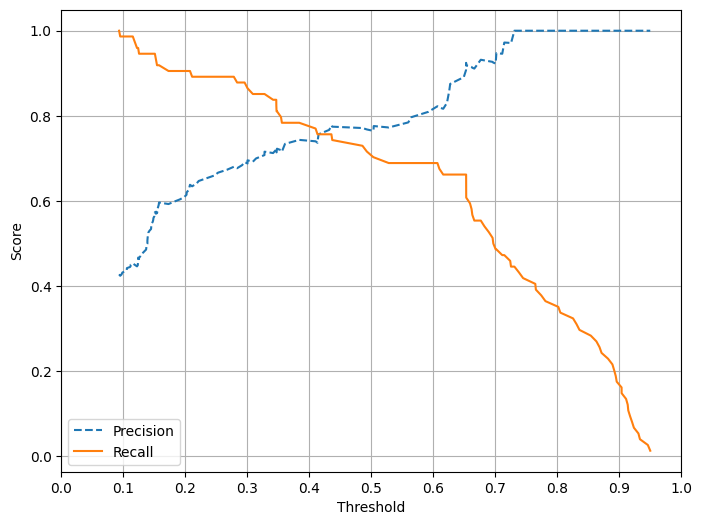

In [9]:
import matplotlib.pyplot as plt
from sklearn.metrics import precision_recall_curve as sklearn_precision_recall_curve


def plot_precision_recall_curve(y_true, pred_proba_class1):
    precisions, recalls, thresholds = sklearn_precision_recall_curve(
        y_true, pred_proba_class1
    )
    threshold_count = len(thresholds)

    plt.figure(figsize=(8, 6))
    plt.plot(thresholds, precisions[:threshold_count], "--", label="Precision")
    plt.plot(thresholds, recalls[:threshold_count], label="Recall")
    plt.xticks(np.round(np.arange(0, 1.01, 0.1), 2))
    plt.xlabel("Threshold")
    plt.ylabel("Score")
    plt.legend()
    plt.grid(True)
    plt.show()


plot_precision_recall_curve(y_test, lr_slf.predict_proba(X_test)[:, 1])


In [10]:
from sklearn.metrics import f1_score

f1 = f1_score(y_test, pred)
print(f1)

0.7323943661971832


In [11]:
from sklearn.metrics import roc_curve

pred_proba_class1 = lr_slf.predict_proba(X_test)[:,1]

fprs , tprs, thresholds = roc_curve ( y_test, pred_proba_class1)
thr_index = np.arange(1, thresholds.shape[0], 5)
print(np.round(fprs[thr_index],3))
print(np.round(tprs[thr_index],3))

[0.    0.019 0.038 0.152 0.219 0.267 0.295 0.486 0.648 0.838]
[0.014 0.486 0.662 0.703 0.811 0.851 0.892 0.919 0.946 0.986]


In [12]:
from sklearn.metrics import roc_auc_score

pred_proba_class1 = lr_slf.predict_proba(X_test)[:, 1]
roc_score = roc_auc_score(y_test, pred_proba_class1)

print(roc_score)


0.8787644787644788


In [13]:
from sklearn.metrics import roc_auc_score

pred_proba_class1 = lr_slf.predict_proba(X_test)[:, 1]
roc_score = roc_auc_score(y_test, pred_proba_class1)

print(roc_score)


0.8787644787644788
